# 06 - Comparación y conclusiones

**Objetivo:** comparar los dos enfoques de tópicos —**BERTopic** (04) y **KeyBERT + K-means** (05)— en utilidad e interpretabilidad, con las mismas métricas y los mismos datos, y cerrar con conclusiones y limitaciones.

## Resumen

| Pregunta | Respuesta |
| --- | --- |
| ¿De qué se habla en los tweets de abril–junio de 2009? | Sobre todo de **la vida diaria**: trabajo, escuela, dormir, comida, clima, saludos, estados de ánimo, Twitter. Lo confirman el EDA y los dos modelos |
| ¿Aparecen eventos reales? | Sí: **22 de 34 eventos candidatos** tienen un tópico propio en BERTopic con pico en la fecha que dan las fuentes. Entre ellos, 6 que no estaban en las hipótesis iniciales |
| ¿Qué enfoque sirve para qué? | **BERTopic** para encontrar **qué pasó cada día** (tópicos finos, eventos). **KeyBERT + K-means** para describir **de qué se habla en general** (50 temas amplios, nombrables a mano) |
| ¿Coinciden? | Moderadamente (AMI 0,40). Los eventos que encuentra BERTopic están dentro de K-means, mezclados en clusters temáticos amplios (*Famosos*, *Películas y TV*, *Enfermedad*) |
| ¿Cuál agrupa mejor tweets del mismo tema en un control externo? | BERTopic (AMI con la búsqueda de origen: 0,53 contra 0,40) |

#### Dependencias

In [1]:
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
import torch
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
from keybert import KeyBERT
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import adjusted_mutual_info_score, silhouette_score
from sklearn.preprocessing import normalize

import utils

warnings.filterwarnings("ignore", category=FutureWarning)

#### Parámetros

In [2]:
RANDOM_STATE = 42
HILOS = 8
MIN_DF = 10              # mismo vocabulario que en la 04 y la 05
N_SILHOUETTE = 10_000
MIN_TWEETS_QUERY = 10    # búsquedas del archivo de test con al menos 10 tweets

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
torch.set_num_threads(HILOS)
rng = np.random.default_rng(RANDOM_STATE)

#### Funciones

In [3]:
def palabras_kmeans(grupos, k, n=10):
    """Top-n términos c-TF-IDF de cada cluster (mismo cálculo que en la 05)."""
    validos = np.where(grupos >= 0)[0]
    indicadora = sp.csr_matrix((np.ones(len(validos)), (grupos[validos], validos)), shape=(k, len(docs)))
    puntajes = ClassTfidfTransformer(reduce_frequent_words=True).fit_transform(indicadora @ X_conteo).toarray()
    return [[vocab[j] for j in np.argsort(-puntajes[c])[:n]] for c in range(k)]


def representacion_A(claves, emb_claves):
    """Promedio de embeddings de las palabras clave, ponderado por puntaje (como en la 05)."""
    rep = np.zeros((len(claves), 384), dtype=np.float32)
    for i, k in enumerate(claves):
        if k:
            pesos = np.array([max(s, 0.01) for _, s in k])
            rep[i] = (pesos[:, None] * np.array([emb_claves[w] for w, _ in k])).sum(axis=0)
    return normalize(rep)


def pureza(etiquetas, grupos):
    """% de los elementos de cada etiqueta que caen en su grupo más frecuente."""
    d = pd.DataFrame({"etiqueta": etiquetas, "grupo": grupos})
    return d.groupby("etiqueta")["grupo"].agg(lambda s: s.value_counts(normalize=True).iloc[0])

## 1. Carga

In [4]:
muestra = utils.cargar_muestra()
emb = utils.cargar_embeddings(len(muestra))
docs = muestra["texto_limpio"].tolist()
textos = muestra["texto_limpio"].str.lower()

asig_bt = pd.read_csv(utils.PROCESSED_DIR / "topicos_bertopic.csv")
asig_km = pd.read_csv(utils.PROCESSED_DIR / "clusters_kmeans.csv")
assert (asig_bt["id"].to_numpy() == muestra["id"].to_numpy()).all()
assert (asig_km["id"].to_numpy() == muestra["id"].to_numpy()).all()
topicos = asig_bt["topico"].to_numpy()
clusters = asig_km["cluster"].to_numpy()
nombres_km = asig_km[asig_km["cluster"] >= 0].drop_duplicates("cluster").set_index("cluster")["nombre"].sort_index()

modelo_emb = SentenceTransformer(utils.MODELO_EMBEDDINGS, device="cpu")
modelo_bt = BERTopic.load(str(utils.MODELS_DIR / "bertopic"), embedding_model=modelo_emb)

vectorizador = CountVectorizer(stop_words=utils.STOPWORDS, token_pattern=utils.TOKEN_PATTERN,
                               ngram_range=(1, 2), min_df=MIN_DF)
X_conteo = vectorizador.fit_transform(docs)
vocab = vectorizador.get_feature_names_out()
X_bin = X_conteo.copy()
X_bin.data[:] = 1
X_bin = X_bin.tocsc()

guardado = pd.read_csv(utils.PROCESSED_DIR / "palabras_clave.csv.gz", keep_default_na=False)
claves = [[(w, float(s)) for w, s in zip(p.split("|"), q.split("|"))] if p else []
          for p, q in zip(guardado["palabras_clave"], guardado["puntajes"])]
unicas = sorted({w for k in claves for w, _ in k})
emb_claves = dict(zip(unicas, modelo_emb.encode(unicas, batch_size=64, normalize_embeddings=True,
                                                show_progress_bar=False)))
rep_A = representacion_A(claves, emb_claves)

print(f"{len(docs):,} tweets | BERTopic: {len(modelo_bt.get_topics()) - 1} tópicos | K-means: {len(nombres_km)} clusters")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

217,133 tweets | BERTopic: 549 tópicos | K-means: 50 clusters


## 2. Comparación cuantitativa

Mismas métricas para los dos enfoques, sobre los mismos 217 mil tweets. Las palabras de cada grupo salen del mismo c-TF-IDF, así que las diferencias se deben al **agrupamiento**.

In [5]:
def fila_metricas(grupos, palabras, eventos_csv, silhouette=np.nan):
    asignados = grupos != -1
    pmi, _ = utils.pmi_grupo_dia(grupos, muestra["dia"])
    ev = pd.read_csv(utils.PROCESSED_DIR / eventos_csv)
    return {
        "tópicos": len(palabras),
        "% tweets asignados": asignados.mean() * 100,
        "tamaño mediano": np.median(np.bincount(grupos[asignados])),
        "NPMI": np.nanmean(utils.coherencia_npmi(palabras, X_bin, vocab)),
        "coherencia embeddings": np.nanmean(utils.coherencia_embeddings(palabras, modelo_emb)),
        "diversidad": utils.diversidad(palabras),
        "silhouette": silhouette,
        "tópicos con PMI día ≥ 3": int((pmi.max(axis=1) >= 3).sum()),
        "eventos confirmados (de 34)": int(ev["confirmado"].sum()),
    }

palabras_bt = [[w for w, _ in modelo_bt.get_topic(t)[:10]] for t in sorted(modelo_bt.get_topics()) if t != -1]
palabras_km = palabras_kmeans(clusters, len(nombres_km))

con = np.where(clusters >= 0)[0]
s = rng.choice(con, N_SILHOUETTE, replace=False)
sil_km = silhouette_score(rep_A[s], clusters[s], metric="cosine")

comparacion = pd.DataFrame({
    "BERTopic": fila_metricas(topicos, palabras_bt, "validacion_bertopic.csv"),
    "KeyBERT + K-means": fila_metricas(clusters, palabras_km, "validacion_kmeans.csv", sil_km),
}).round(3)
comparacion

,BERTopic,KeyBERT + K-means
tópicos,549.000,50.000
% tweets asignados,56.731,99.280
tamaño mediano,123.000,3683.000
NPMI,-0.597,-0.170
coherencia embeddings,0.332,0.518
diversidad,0.732,0.986
silhouette,NaN,0.061
tópicos con PMI día ≥ 3,33.000,1.000
eventos confirmados (de 34),22.000,1.000


- **Coherencia y diversidad favorecen a K-means.** Sus tópicos son amplios y se describen con palabras frecuentes que aparecen juntas más seguido. BERTopic tiene muchos tópicos chicos, con palabras más específicas y a veces repetidas entre tópicos parecidos.
- **Utilidad para encontrar eventos favorece claramente a BERTopic**: 33 tópicos con un pico fuerte en un día y 22 eventos confirmados, contra 1 de K-means.
- La silhouette solo aplica a K-means (en BERTopic, HDBSCAN deja outliers y no busca grupos esféricos). Su valor bajo indica que los temas de los tweets son un continuo, no grupos separados.
- **Las métricas de coherencia no alcanzan para elegir.** Miden si las palabras de un tópico "van juntas", no si el tópico responde la pregunta del análisis.

## 3. Eventos: lado a lado

Mismo criterio en los dos enfoques: grupo propio (precisión ≥ 50%) y pico ±1 día de la fecha de la fuente (`eventos.py`).

In [6]:
v_bt = pd.read_csv(utils.PROCESSED_DIR / "validacion_bertopic.csv")
v_km = pd.read_csv(utils.PROCESSED_DIR / "validacion_kmeans.csv")
lado = pd.DataFrame({
    "evento": v_bt["evento"],
    "origen": v_bt["origen"],
    "fecha fuente": v_bt["fecha fuente"],
    "BERTopic: tópico": [", ".join(w for w, _ in modelo_bt.get_topic(int(g))[:3]) if pd.notna(g) else "" for g in v_bt["grupo"]],
    "BERTopic: precisión": v_bt["precisión"],
    "BERTopic ✓": v_bt["confirmado"].map({True: "sí", False: ""}),
    "K-means: cluster": [nombres_km[int(g)] if pd.notna(g) else "" for g in v_km["grupo"]],
    "K-means: precisión": v_km["precisión"],
    "K-means ✓": v_km["confirmado"].map({True: "sí", False: ""}),
})
print(f"Confirmados — BERTopic: {v_bt['confirmado'].sum()} | K-means: {v_km['confirmado'].sum()} | "
      f"ninguno: {(~v_bt['confirmado'] & ~v_km['confirmado']).sum()}")
lado

Confirmados — BERTopic: 22 | K-means: 1 | ninguno: 12


,evento,origen,fecha fuente,BERTopic: tópico,BERTopic: precisión,BERTopic ✓,K-means: cluster,K-means: precisión,K-means ✓
0,Pascua,EDA,12/04,"eggs, egg, easter",0.16,,Comida,0.00,
1,Oracle anuncia la compra de Sun,EDA,20/04,"ellen, holly, paris",0.01,,Sol y verano,0.00,
2,Gripe porcina: la OMS sube la alerta a fase 4 y 5,EDA,27/04 y 29/04,"swine, flu, cases",0.80,sí,"Enfermedad (resfrío, gripe porcina)",0.07,
3,Estreno de X-Men Origins: Wolverine,EDA,01/05,"men, hugh, great good",0.66,sí,"Personas por nombre (Jonas, Idol, Carradine)",0.01,
4,Pelea Pacquiao–Hatton,EDA,02/05,"gym, workout, fitness",0.00,,"Personas por nombre (Jonas, Idol, Carradine)",0.00,
5,Estreno de Star Trek,EDA,08/05,"star trek, trek, star",0.82,sí,Películas y TV,0.04,
6,Día de la Madre (EE. UU.),EDA,10/05,"happy mother's, happy mothers, mother's day",0.68,sí,Día de la Madre y del Padre,0.64,sí
7,Danny Gokey eliminado de American Idol,EDA,13/05,"danny, american idol, idol",0.26,,"Personas por nombre (Jonas, Idol, Carradine)",0.02,
8,Final de Eurovisión,EDA,16/05,"itunes, downloading, downloads",0.01,,Música,0.00,
9,Lanzamiento de Wolfram Alpha,EDA,15/05 y 18/05,"math, maths, exam",0.01,,"Lectura, escritura y tareas",0.00,


**¿Dónde quedan, en K-means, los eventos que BERTopic sí encontró?**

In [7]:
confirmados = v_bt[v_bt["confirmado"]]
filas = []
for _, r in confirmados.iterrows():
    reparto = pd.Series(clusters[topicos == r["grupo"]]).value_counts(normalize=True)
    filas.append({"evento": r["evento"], "tópico BERTopic": int(r["grupo"]),
                  "cluster K-means principal": nombres_km[reparto.index[0]],
                  "% del tópico en ese cluster": round(reparto.iloc[0] * 100)})
donde = pd.DataFrame(filas)
print(f"Mediana: {donde['% del tópico en ese cluster'].median():.0f}% del tópico en un solo cluster")
donde

Mediana: 44% del tópico en un solo cluster


,evento,tópico BERTopic,cluster K-means principal,% del tópico en ese cluster
0,Gripe porcina: la OMS sube la alerta a fase 4 y 5,115,"Enfermedad (resfrío, gripe porcina)",71
1,Estreno de X-Men Origins: Wolverine,164,"Personas por nombre (Jonas, Idol, Carradine)",43
2,Estreno de Star Trek,86,Películas y TV,72
3,Día de la Madre (EE. UU.),16,Día de la Madre y del Padre,74
4,Final de Britain's Got Talent,489,"Misceláneo (votos, juegos, charla suelta)",28
5,MTV Movie Awards,300,Películas y TV,72
6,Adelanto de New Moon (en los MTV Movie Awards),308,Películas y TV,38
7,Último Tonight Show de Leno / debut de Conan,452,"Personas por nombre (Jonas, Idol, Carradine)",60
8,Air France 447 cae en el Atlántico,277,Transporte,44
9,E3 y Project Natal,515,Computadoras,26


- Los eventos **están dentro de K-means**. Cuando un tópico de evento cae mayormente en un cluster, es el que uno esperaría: Farrah Fawcett (83%) y Jon & Kate en *Famosos*, la gripe porcina en *Enfermedad*, los estrenos en *Películas y TV*, Carradine en *Personas por nombre*, el metro de Washington y Air France en *Transporte*.
- Pero en esos clusters son una minoría: *Películas y TV* tiene más de 5 mil tweets y el tópico de Star Trek, unos 300. Por eso su pico diario no se nota.
- Los eventos con menor concentración en un cluster (feriado bancario, E3, *True Blood*, *Britain's Got Talent*) son los que K-means reparte entre varios temas.

## 4. ¿Coinciden los dos enfoques?

**Información mutua ajustada (AMI):** mide cuánto se parecen dos formas de agrupar los mismos tweets. La información mutua es el promedio de la PMI sobre todos los pares (tópico, cluster); la versión ajustada descuenta lo que coincidiría por azar. 0 = independientes, 1 = idénticas.

AMI BERTopic vs K-means (tweets asignados en ambos): 0.402
Pureza de los tópicos de BERTopic dentro de K-means: mediana 0.49 | tópicos con más de la mitad en un solo cluster: 48%


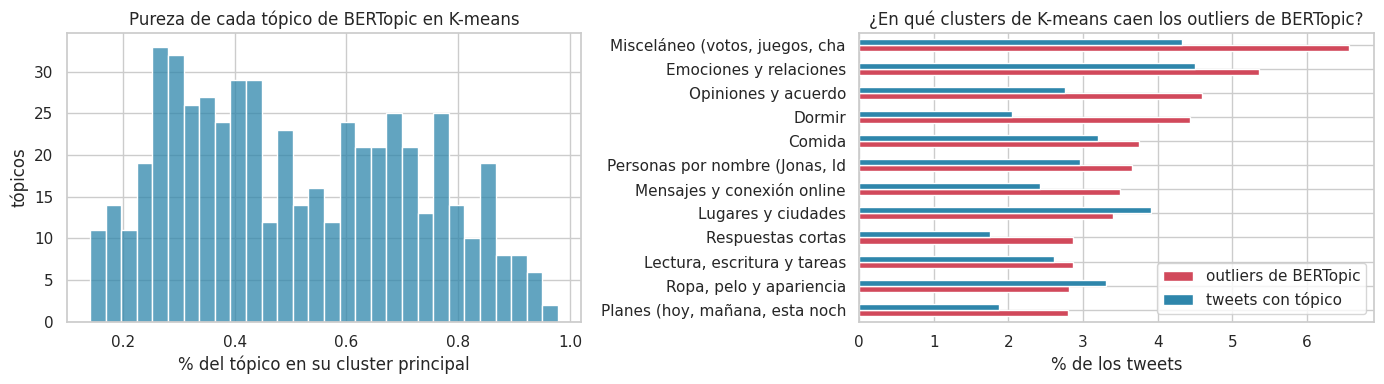

In [8]:
ambos = (topicos != -1) & (clusters != -1)
ami = adjusted_mutual_info_score(topicos[ambos], clusters[ambos])
pur = pureza(topicos[ambos], clusters[ambos])
print(f"AMI BERTopic vs K-means (tweets asignados en ambos): {ami:.3f}")
print(f"Pureza de los tópicos de BERTopic dentro de K-means: mediana {pur.median():.2f} | "
      f"tópicos con más de la mitad en un solo cluster: {(pur > 0.5).mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(pur, bins=30, ax=axes[0], color="#2e86ab")
axes[0].set(title="Pureza de cada tópico de BERTopic en K-means", xlabel="% del tópico en su cluster principal", ylabel="tópicos")

reparto = pd.DataFrame({
    "outliers de BERTopic": pd.Series(clusters[(topicos == -1) & (clusters >= 0)]).value_counts(normalize=True),
    "tweets con tópico": pd.Series(clusters[ambos]).value_counts(normalize=True),
}).fillna(0) * 100
reparto.index = nombres_km[reparto.index].str[:30]
reparto.sort_values("outliers de BERTopic", ascending=False).head(12)[::-1].plot.barh(ax=axes[1], color=["#d1495b", "#2e86ab"])
axes[1].set(title="¿En qué clusters de K-means caen los outliers de BERTopic?", xlabel="% de los tweets", ylabel="")
plt.tight_layout()
plt.show()

- La concordancia es **moderada** (AMI ~0,40): los dos enfoques ven estructura parecida, pero no igual. BERTopic agrupa por el significado del tweet completo; K-means, por el de sus 3 palabras clave.
- Los tópicos de BERTopic **no están limpiamente anidados** en los clusters de K-means: en la mediana, la mitad de un tópico cae en un solo cluster. El histograma tiene dos grupos: tópicos repartidos (~30% en su cluster principal) y tópicos que son casi un subtema de un cluster (~70%). Los de eventos se comportan igual (mediana 44%, sección 3).
- **Los outliers de BERTopic se reparten en todos los clusters de K-means**, con más peso en los de conversación genérica (*Misceláneo*, *Emociones*, *Opiniones*, *Respuestas cortas*, *Dormir*). No son basura: es charla cotidiana que no forma zonas densas. K-means la asigna igual porque está obligado a asignar todo.

## 5. Control externo: el archivo de test

Los 498 tweets del archivo de test se juntaron buscando un tema (`query`): marcas, productos, personas. Es una etiqueta de "de qué habla el tweet" que los modelos nunca vieron.

- **BERTopic:** cada tweet se asigna al tópico más parecido por **similitud coseno** entre su embedding y el embedding del tópico.
- **K-means:** se extraen sus palabras clave con KeyBERT, se arma la representación A y se asigna al **centroide** más cercano. El vectorizador se ajusta sobre estos 498 tweets (KeyBERT lo reajusta sobre los textos que recibe).

Si un modelo agrupa bien por tema, los tweets de una misma búsqueda deberían caer en el mismo grupo.

In [9]:
test = utils.leer_tweets(utils.FILE_TEST)
test["texto_limpio"] = utils.limpiar_texto(test["texto"])
emb_test = modelo_emb.encode(test["texto_limpio"].tolist(), normalize_embeddings=True, show_progress_bar=False)

# BERTopic: tópico más parecido (la fila 0 de topic_embeddings_ es el -1)
ids_bt = np.array(sorted(t for t in modelo_bt.get_topics() if t != -1))
centros_bt = normalize(modelo_bt.topic_embeddings_[1:])
test["bertopic"] = ids_bt[np.argmax(emb_test @ centros_bt.T, axis=1)]

# K-means: palabras clave -> representación A -> centroide más cercano
centros_km = normalize(np.vstack([rep_A[clusters == c].mean(axis=0) for c in nombres_km.index]))
vect_test = CountVectorizer(stop_words=utils.STOPWORDS, token_pattern=utils.TOKEN_PATTERN, ngram_range=(1, 2))
claves_test = KeyBERT(model=modelo_emb).extract_keywords(
    test["texto_limpio"].tolist(), vectorizer=vect_test, top_n=3, use_mmr=True, diversity=0.5, doc_embeddings=emb_test)
nuevas = sorted({w for k in claves_test for w, _ in k} - set(emb_claves))
emb_claves |= dict(zip(nuevas, modelo_emb.encode(nuevas, normalize_embeddings=True, show_progress_bar=False)))
rep_test = representacion_A(claves_test, emb_claves)
test["kmeans"] = np.where(np.linalg.norm(rep_test, axis=1) > 0, np.argmax(rep_test @ centros_km.T, axis=1), -1)

frecuentes = test["query"].value_counts().loc[lambda s: s >= MIN_TWEETS_QUERY].index
sub = test[test["query"].isin(frecuentes)]
filas = []
for q in frecuentes:
    g = sub[sub["query"] == q]
    b, k = g["bertopic"].value_counts(), g["kmeans"].value_counts()
    filas.append({"búsqueda": q, "tweets": len(g),
                  "BERTopic: tópico principal": ", ".join(w for w, _ in modelo_bt.get_topic(int(b.index[0]))[:3]),
                  "BERTopic: pureza": round(b.iloc[0] / len(g), 2),
                  "K-means: cluster principal": nombres_km.get(k.index[0], "sin palabras clave"),
                  "K-means: pureza": round(k.iloc[0] / len(g), 2)})
control = pd.DataFrame(filas)

print(f"{len(frecuentes)} búsquedas con {MIN_TWEETS_QUERY}+ tweets ({len(sub)} tweets)")
print(f"AMI búsqueda vs BERTopic: {adjusted_mutual_info_score(sub['query'], sub['bertopic']):.3f} | "
      f"búsqueda vs K-means: {adjusted_mutual_info_score(sub['query'], sub['kmeans']):.3f}")
print(f"Pureza media — BERTopic: {control['BERTopic: pureza'].mean():.2f} | K-means: {control['K-means: pureza'].mean():.2f}")
control

15 búsquedas con 10+ tweets (271 tweets)
AMI búsqueda vs BERTopic: 0.534 | búsqueda vs K-means: 0.401
Pureza media — BERTopic: 0.49 | K-means: 0.51


,búsqueda,tweets,BERTopic: tópico principal,BERTopic: pureza,K-means: cluster principal,K-means: pureza
0,time warner,35,"internet, wifi, wireless",0.46,Películas y TV,0.40
1,"""night at the museum""",25,"movies, movie, good movie",0.52,Buenas noches,0.44
2,nike,25,"shoes, shoe, boots",0.72,"Ropa, pelo y apariencia",0.44
3,gm,22,"recession, economy, pay",0.23,Transporte,0.32
4,kindle2,20,"new iphone, iphone, ordered new",0.35,"Celulares (iPhone, BlackBerry)",0.70
5,safeway,20,"traffic, jam, bridge",0.15,Transporte,0.30
6,lebron,18,"magic, nba, playoffs",0.83,"Personas por nombre (Jonas, Idol, Carradine)",0.61
7,dentist,17,"dentist, teeth, tooth",0.82,Dolores,0.35
8,jquery,16,"firefox, browser, opera",0.44,Computadoras,0.56
9,at&t,15,"new phone, cell, cell phone",0.13,"Celulares (iPhone, BlackBerry)",0.27


- **BERTopic separa mejor las búsquedas** (AMI más alta). Cuando una búsqueda es un tema concreto, cae casi entera en un tópico específico: `obama` en un tópico de política (`president`, `speech`), `twitter api`, `lebron` en el de la NBA, `dentist` en el de dentistas, `nike` en el de zapatillas. También acierta el ángulo: `time warner` va a un tópico de internet y `gm` a uno de economía y recesión.
- **K-means agrupa por tema amplio:** `kindle2` va a *Celulares*, `eating` a *Comida*, `jquery` a *Computadoras*. Por eso, a veces, su pureza es igual o mayor: todos los tweets de un tema caen en el mismo cluster grande, pero junto con otras búsquedas (AMI más baja).
- Un error típico de las palabras clave: *night at the museum* (la película *Una noche en el museo*) cae en **Buenas noches** por la palabra `night`. BERTopic, que usa el tweet completo, la pone en un tópico de películas.
- Búsquedas con opiniones muy variadas (`at&t`, `safeway`, `gm`) se reparten en los dos enfoques: los tweets hablan de cosas distintas (señal, tráfico, economía) aunque nombren la misma marca.

## 6. Métricas usadas y qué aportó cada una

| Métrica | Dónde | Qué aportó |
| --- | --- | --- |
| **PMI** (bigramas) | 02 | Encontrar expresiones con significado propio (`farrah fawcett`, `swine flu`) → justificó usar bigramas |
| **PMI palabra–día / tópico–día** | 02, 04, 05 | Encontrar **cuándo** algo es noticia, con proporciones (inmune al volumen desparejo de cada día). Es la base de la validación de eventos |
| **NPMI** (coherencia) | 04, 05, 06 | Si las palabras de un tópico aparecen juntas en los tweets. Negativa en textos tan cortos: útil para **comparar**, no como valor absoluto |
| **Similitud coseno** | 03, 04, 05, 06 | Vecinos de un tweet, puntaje de KeyBERT, coherencia por embeddings, similitud entre tópicos, reasignación de outliers, asignación del archivo de test |
| **Silhouette** e **inercia** | 05 | Elegir K. Mostraron que no hay grupos bien separados (silhouette < 0,1, sin codo) |
| **Precisión / recall** contra eventos | 04, 05, 06 | Medir si un grupo **trata de** un evento (precisión) y si lo **reúne** (recall). Con las fuentes, definen "evento confirmado" |
| **AMI** | 06 | Concordancia entre enfoques y contra un etiquetado externo (`query`) |

## 7. Conclusiones

**¿Qué enfoque sirvió más?** Depende de la pregunta:

| Objetivo | Enfoque recomendado | Por qué |
| --- | --- | --- |
| Encontrar **eventos** y fecharlos | **BERTopic** | Tópicos finos sin fijar cuántos, outliers fuera, eventos que aparecen solos con su pico. 22 de 34 eventos confirmados, 6 que no estaban en las hipótesis |
| Describir **de qué se habla en general** | **KeyBERT + K-means** | 50 temas amplios, todos los tweets asignados, fáciles de nombrar y de agrupar en 3 macrotemas |
| Explicar un resultado a otra persona | **KeyBERT + K-means** | Palabras clave por tweet y nombres elegidos a mano. Las 549 etiquetas automáticas de BERTopic a veces confunden |
| Agrupar tweets nuevos por tema concreto | **BERTopic** | Separa mejor las búsquedas del archivo de test |

**Hallazgos principales**
- Los tweets de Sentiment140 son **mayormente charla personal**: es consecuencia de cómo se juntaron (buscando emoticones).
- Aun así, los eventos del período **dejan huella**: muertes de famosos, estrenos, finales de programas, lanzamientos, noticias. Aparecen como tópicos chicos y muy concentrados en uno o dos días.
- La **PMI con proporciones por día** fue la herramienta más útil: generó las hipótesis en el EDA y después permitió encontrar los eventos entre cientos de tópicos.
- **Ningún modelo confirma un evento por sí solo.** El modelo agrupa; el pico en el tiempo y una fuente externa confirman.

**Limitaciones**
- **Sesgo de recolección:** tweets elegidos por emoticones, en inglés. No es una muestra de "lo que se tuiteaba" en 2009.
- **Huecos y volumen artificial:** 48 de 81 días con datos y volumen diario definido por el recolector. Los eventos en huecos (Pascua) no pueden aparecer, y Michael Jackson queda afuera por horas.
- **Muestra:** 217 mil de 1,5 M tweets por límites de CPU. Los eventos con menos de ~50 tweets en la muestra (Oracle–Sun, Eurovisión, Pacquiao–Hatton) no llegan a formar tópico.
- **Precisión medida por palabras clave:** es una cota inferior. Muchos tweets hablan de un evento sin nombrarlo (*"RIP Ed"*, «QEPD Ed»).
- **Una sola semilla:** no se midió la estabilidad de UMAP, HDBSCAN y K-means con otras semillas.
- **Fuentes:** las fechas se verificaron en Wikipedia y en los medios que cita. Para fechas que siguen una regla (Día de la Madre, Pascua) se usó la regla.

**Posibles mejoras**
- Usar los 1,5 M de tweets con GPU, para que los eventos chicos formen tópico.
- Probar `min_cluster_size` por debajo de 50 o un BERTopic por semana (*online topic modeling*) para eventos de un solo día.
- Unir tópicos repetidos (`reduce_topics`) solo entre los cotidianos, para conservar el detalle de los eventos.
- Medir la estabilidad con varias semillas.